In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas
import os

In [2]:
input_dir = "../../results_1kb_spacing/FET_pvals/loose_unlinked/"
filenames = [x for x in os.listdir(input_dir) if "p_bins" in x]

In [3]:
sums = 0
for filename in filenames:
    sums += np.loadtxt(input_dir + filename)[:, 1]
np.savetxt("../../results_1kb_spacing/FET_pvals/sum_p_bins_unlinked.txt", sums)

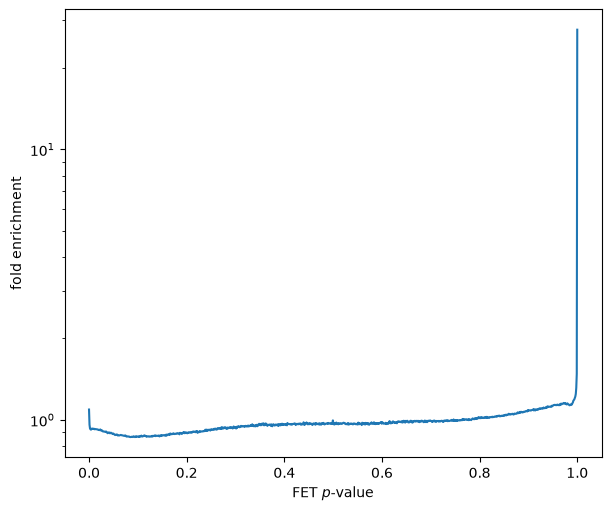

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), layout="constrained")
ax.plot(np.linspace(0,1,1000), sums/np.mean(sums))
ax.set_yscale("log")
ax.set_xlabel("FET $p$-value")
ax.set_ylabel("fold enrichment")
plt.savefig("../../figures/FET_p_values_unlinked.png", dpi=244)

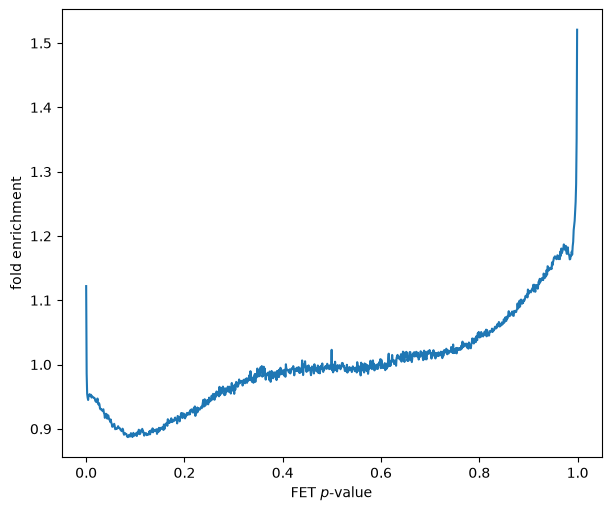

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), layout="constrained")
ax.plot(np.linspace(0,1,1000)[:-1], sums[:-1]/np.mean(sums[:-1]))
ax.set_xlabel("FET $p$-value")
ax.set_ylabel("fold enrichment")
plt.savefig("../../figures/FET_p_values_unlinked_discard_last_bin.png", dpi=244)

In [15]:
df = pandas.read_csv("../../results_1kb_spacing/FET_pvals/sites_unlinked.tsv", sep="\\s+",
                    names=["chrom1", "position1", "chrom2", "position2", "p", "EE", "EA", "AE", "AA"])
ps = np.array(df["p"])

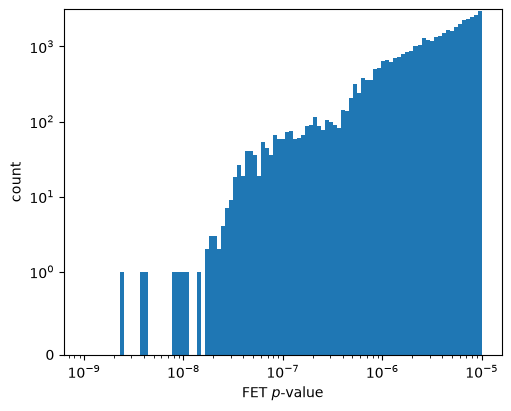

In [23]:
bins = np.logspace(-9, -5, 100)
fig, ax = plt.subplots(1, 1, figsize=(5, 4), layout="constrained")
ax.hist(ps, bins=bins)
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylabel("count")
ax.set_xlabel("FET $p$-value")
plt.savefig("../../figures/FET_small_p_values_unlinked.png", dpi=244)

In [17]:
print(df.iloc[np.argmin(ps)])

chrom1             2R
position1    15613250
chrom2             3R
position2    10476097
p                 0.0
EE                721
EA                 48
AE                103
AA                 33
Name: 35012, dtype: object


In [20]:
EE = 721
EA = 48
AE = 103
AA = 33
N = EE + EA + AE + AA
A1 = (AE + AA) / N
A2 = (AA + EA) / N
E1 = (EE + EA) / N
E2 = (AE + EE) / N
print(E1 * E2 * N)
print(E1 * A2 * N)
print(A1 * E2 * N)
print(A1 * A2 * N)

700.1723756906077
68.82762430939228
123.82762430939226
12.172375690607735


In [21]:
scipy.stats.fisher_exact([[0, 10], [10, 980]], alternative="greater")

SignificanceResult(statistic=np.float64(0.0), pvalue=np.float64(1.0))